# Validación de un modelo de impago con UCI

## Pregunta
¿Se mantienen discriminación y calibración en una muestra retenida de clientes de tarjetas del mismo periodo? Comparamos entrenamiento y prueba con separación aleatoria estratificada. El conjunto es Taiwán, 2005; no dispone de fecha individual de originación y esta prueba no es fuera de tiempo ni valida un modelo institucional.

## Fuente y diseño
[Yeh, 2009, UCI Default of Credit Card Clients](https://doi.org/10.24432/C55S3H), CC BY 4.0; 30.000 clientes y etiqueta de impago el mes siguiente. Se usa el mismo archivo público que el [scorecard WoE](../../../01-credit-risk/credit-risk-products/scorecard-logistico-woe/observed-uci350/README.md), pero se ajusta aquí una regresión logística numérica independiente, no el scorecard WoE. No usamos identificador, sexo, edad ni estado civil como predictores; `PAY_*` registra comportamiento anterior y no es un predictor de originación garantizado.

In [1]:
from pathlib import Path
import hashlib, numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score,brier_score_loss,roc_curve
root=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'03-financial-risk').is_dir())
p=root/'03-financial-risk/01-credit-risk/credit-risk-products/scorecard-logistico-woe/observed-uci350/data/default-of-credit-card-clients.xls'
sha=hashlib.sha256(p.read_bytes()).hexdigest(); assert sha=='30c6be3abd8dcfd3e6096c828bad8c2f011238620f5369220bd60cfc82700933'
d=pd.read_excel(p,header=1);cols=['LIMIT_BAL','PAY_0','PAY_2','PAY_3','PAY_4'];target='default payment next month'
assert len(d)==30000 and d.ID.is_unique and d[cols+[target]].notna().all().all() and d[target].isin([0,1]).all()
train,test=train_test_split(d,test_size=.25,stratify=d[target],random_state=42);assert set(train.ID).isdisjoint(set(test.ID))
model=make_pipeline(StandardScaler(),LogisticRegression(max_iter=1000,random_state=42));model.fit(train[cols],train[target])
p_train=model.predict_proba(train[cols])[:,1];p_test=model.predict_proba(test[cols])[:,1]
print('SHA-256:',sha,'| Entrenamiento:',len(train),'| Prueba:',len(test))

SHA-256: 30c6be3abd8dcfd3e6096c828bad8c2f011238620f5369220bd60cfc82700933 | Entrenamiento: 22500 | Prueba: 7500


## Discriminación y calibración
El Gini es $2\,AUC-1$. El error Brier promedia $(\hat p-y)^2$; menor no significa por sí solo que el modelo sea suficientemente calibrado. Los intervalos de score se fijan por cuantiles del entrenamiento y se aplican sin reajuste a la muestra de prueba.

In [2]:
rows=[]
for name,frame,prob in [('Entrenamiento',train,p_train),('Prueba aleatoria',test,p_test)]:
    auc=roc_auc_score(frame[target],prob);fpr,tpr,_=roc_curve(frame[target],prob)
    rows.append({'muestra':name,'n':len(frame),'eventos':int(frame[target].sum()),'auc':auc,'gini':2*auc-1,'ks':float((tpr-fpr).max()),'brier':brier_score_loss(frame[target],prob),'pd_media':prob.mean(),'tasa_observada':frame[target].mean()})
summary=pd.DataFrame(rows);display(summary.round(4))
edges=np.unique(np.quantile(p_train,np.linspace(0,1,11)));edges[0]=-np.inf;edges[-1]=np.inf
assert len(edges)>2
def tab(frame,prob):
    tmp=pd.DataFrame({'pd':prob,'evento':frame[target].to_numpy()});tmp['bin']=pd.cut(tmp.pd,edges,include_lowest=True,labels=False)
    return tmp.groupby('bin').agg(n=('evento','size'),eventos=('evento','sum'),pd_media=('pd','mean'),tasa=('evento','mean')).reindex(range(len(edges)-1),fill_value=0)
a=tab(train,p_train);b=tab(test,p_test);display(b.round(4))

,muestra,n,eventos,auc,gini,ks,brier,pd_media,tasa_observada
0,Entrenamiento,22500,4977,0.7198,0.4396,0.3901,0.1457,0.2212,0.2212
1,Prueba aleatoria,7500,1659,0.7067,0.4133,0.3701,0.1470,0.2221,0.2212


,n,eventos,pd_media,tasa
bin,,,,
0,761,109,0.0457,0.1432
1,733,90,0.0886,0.1228
2,783,123,0.1214,0.1571
3,788,88,0.1653,0.1117
4,709,86,0.1932,0.1213
5,851,115,0.2137,0.1351
6,709,102,0.2281,0.1439
7,662,143,0.2411,0.2160
8,745,284,0.3549,0.3812


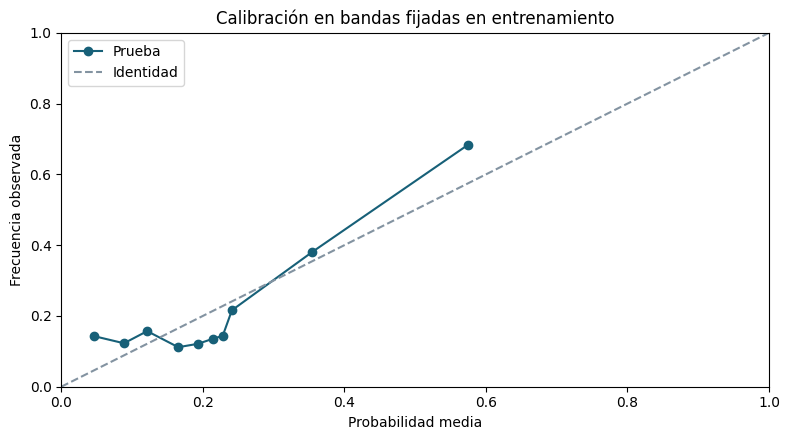

In [3]:
fig,ax=plt.subplots(figsize=(8,4.5));ax.plot(b.pd_media,b.tasa,'o-',color='#176078',label='Prueba');ax.plot([0,1],[0,1],ls='--',color='#8393a1',label='Identidad');ax.set(title='Calibración en bandas fijadas en entrenamiento',xlabel='Probabilidad media',ylabel='Frecuencia observada',xlim=(0,1),ylim=(0,1));ax.legend();plt.tight_layout();plt.show()

## PSI: comparación de distribución, no drift temporal
Para bandas fijas, $PSI=\sum_b (q_b-p_b)\log(q_b/p_b)$, donde $p$ y $q$ son las proporciones de entrenamiento y prueba; se aplica suavizado 0,5 por banda. Estas muestras provienen del mismo periodo y se separaron aleatoriamente: el resultado es una comprobación de partición, no evidencia de estabilidad temporal ni un umbral regulatorio.

In [4]:
k=len(a); pt=(a.n.to_numpy()+.5)/(a.n.sum()+.5*k); qt=(b.n.to_numpy()+.5)/(b.n.sum()+.5*k); contribution=(qt-pt)*np.log(qt/pt); psi=float(contribution.sum())
assert np.isfinite(psi) and psi>=-1e-12
psi_table=pd.DataFrame({'banda':range(1,k+1),'proporcion_entrenamiento':pt,'proporcion_prueba':qt,'contribucion_psi':contribution})
print('PSI del score entre particiones aleatorias:',round(psi,6));display(psi_table.round(5))

PSI del score entre particiones aleatorias: 0.000605


,banda,proporcion_entrenamiento,proporcion_prueba,contribucion_psi
0,1,0.10000,0.10147,0.00002
1,2,0.10027,0.09773,0.00006
2,3,0.09973,0.10440,0.00021
3,4,0.10658,0.10506,0.00002
4,5,0.09827,0.09454,0.00014
5,6,0.11071,0.11346,0.00007
6,7,0.09440,0.09454,0.00000
7,8,0.09054,0.08827,0.00006
8,9,0.09951,0.09933,0.00000
9,10,0.10000,0.10120,0.00001


## Interpretación y límites
Este análisis no es una validación independiente completa: entrenamiento y prueba comparten cohorte, se eligió el método para demostración y no hay evaluaciones por fecha de originación, cambios de política o rechazados. Un PSI bajo no implica ausencia de drift futuro ni buen desempeño. No confundir una banda de score con una categoría regulatoria y no extrapolar el resultado al onboarding colombiano.